# AI Exposure or Post-Pandemic Employment Adjustment? Explaining the Decline in Early-Career Hiring

## Author: Viet Nguyen

This notebook loads the completed analysis panel and contains the descriptive analysis, figures, models, diagnostics, and sensitivity checks. Data construction is documented in `01_data_preparation.ipynb`.


## Introduction

Generative artificial intelligence has created growing concern about how the labor market may change, especially for workers beginning their careers. Recent research has found weaker early-career hiring in industries with greater exposure to generative AI. However, a decline in hiring after 2022 does not necessarily mean that AI caused the decline. Some highly AI-exposed industries also experienced unusually strong employment growth during the COVID-19 pandemic, and their later reduction in hiring may partly reflect an adjustment from that earlier growth. Because these explanations can occur at the same time, it is important to consider post-pandemic employment adjustment when examining the relationship between AI exposure and early-career hiring.

This project asks: **After accounting for employment growth above pre-COVID trends, is greater generative AI exposure associated with a larger decline in hiring among workers ages 22 to 24?** To study this question, I combine quarterly hiring and employment data from the U.S. Census Bureau’s Quarterly Workforce Indicators with occupation-level AI exposure scores developed by Eloundou et al. I use pre-pandemic ACS PUMS employment data to translate the occupation-level scores into national industry-level exposure measures.

The study focuses on three main measures:

- **Early-career hiring**: the quarterly hiring rate for workers ages 22 to 24 within each state-industry group.
- **Generative AI exposure**: an industry-level measure of how much the occupations within an industry could potentially be affected by generative AI.
- **Employment above the pre-COVID predicted trend**: the percentage difference between actual employment in 2022 Q1 through Q3 and the employment predicted from each state-industry group’s 2015–2019 trend.

For the employment-trend measure, I estimate a separate pre-COVID trend for each state-industry group using all-age employment. The trend includes a linear time component and quarter indicators for regular seasonal differences. I then compare predicted employment with actual employment during the first three quarters of 2022. The main hiring analysis defines the post period as beginning in 2023 Q1 and excludes 2022 Q4 as a transition quarter.

This is an observational research project, so the results will be interpreted as associations rather than proof that generative AI caused changes in hiring. The AI-exposure measure represents the potential for workers’ tasks to be affected by generative AI; it does not measure whether firms actually adopted AI or replaced workers. Similarly, employment above its predicted trend does not prove that an industry overhired during the pandemic. The goal is to determine whether AI exposure remains associated with changes in early-career hiring after accounting for one measurable form of post-pandemic employment adjustment.

## Library Import

In [1]:
# Library imports
from pathlib import Path
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyfixest.estimation.api.feols import feols
from pyfixest.estimation.models.feols_ import Feols
from statsmodels.graphics.gofplots import qqplot


## Load the Final Analysis Panel

This notebook begins with the validated panel created by `01_data_preparation.ipynb`. The checks below ensure that the file has the required variables, one row per state-industry-quarter, and observations in both analysis periods.


In [ ]:
# Find the project root
project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / ".git").exists():
    project_root = project_root.parent
if not (project_root / ".git").exists():
    raise FileNotFoundError("Open this notebook from inside the senior-research project.")

final_panel_path = project_root / "data/processed/final_analysis_panel.csv"
if not final_panel_path.is_file():
    raise FileNotFoundError("Run 01_data_preparation.ipynb before this notebook.")

# Preserve Census identifiers as text
primary_analysis_panel = pd.read_csv(
    final_panel_path,
    dtype={"state": "string", "industry": "string", "period": "string"},
)
trend_key = ["state", "industry"]
panel_key = trend_key + ["period"]

required_columns = {
    "state", "state_name", "industry", "industry_name",
    "period", "year", "quarter", "hire_count",
    "hiring_rate_pct", "analysis_period", "post",
    "ai_exposure", "ai_exposure_coverage",
    "employment_above_trend_log_pct",
    "employment_above_trend_linear_pct",
}
missing_columns = required_columns - set(primary_analysis_panel.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"
assert not primary_analysis_panel.duplicated(panel_key).any()
assert primary_analysis_panel["analysis_period"].isin(["pre", "post"]).all()
assert primary_analysis_panel.groupby(trend_key)["post"].nunique().eq(2).all()

print("Loaded:", final_panel_path.relative_to(project_root))
print("Observations:", f"{len(primary_analysis_panel):,}")
print("State-industry groups:", f"{primary_analysis_panel.groupby(trend_key).ngroups:,}")
print("Industries:", primary_analysis_panel["industry"].nunique())
print("Quarters:", primary_analysis_panel["period"].nunique())


## Descriptive Analysis

Before estimating the main model, I summarize the outcome and explanatory variables at their appropriate levels. For hiring, I first calculate each state-industry group’s average rate separately in the pre- and post-periods. This gives every group equal weight even though the two periods contain different numbers of quarters. AI exposure is summarized across industries, while employment above trend is summarized across state-industry groups.

The pre-to-post hiring difference is descriptive. It shows the average change in the sample but does not establish that AI exposure caused the change.

In [17]:
# Average hiring within each group and period
group_period_hiring = (
    primary_analysis_panel
    .groupby(
        trend_key + ["analysis_period"],
        as_index=False,
    )
    .agg(
        average_hiring_rate_pct=(
            "hiring_rate_pct",
            "mean",
        )
    )
)


# Place the pre- and post-period averages on one row
group_hiring_change = (
    group_period_hiring
    .pivot(
        index=trend_key,
        columns="analysis_period",
        values="average_hiring_rate_pct",
    )
    .reset_index()
    .rename_axis(columns=None)
    .rename(
        columns={
            "pre": "pre_hiring_rate_pct",
            "post": "post_hiring_rate_pct",
        }
    )
)

assert group_hiring_change[
    [
        "pre_hiring_rate_pct",
        "post_hiring_rate_pct",
    ]
].notna().all().all()


# Add the group-level research measures
group_characteristics = (
    primary_analysis_panel[
        trend_key
        + [
            "ai_exposure",
            "ai_exposure_coverage",
            "employment_above_trend_log_pct",
        ]
    ]
    .drop_duplicates(trend_key)
)

descriptive_group_data = (
    group_hiring_change
    .merge(
        group_characteristics,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
)

descriptive_group_data["hiring_change_pct_points"] = (
    descriptive_group_data["post_hiring_rate_pct"]
    - descriptive_group_data["pre_hiring_rate_pct"]
)


# Describe AI exposure once per industry
industry_characteristics = (
    primary_analysis_panel[
        [
            "industry",
            "ai_exposure",
            "ai_exposure_coverage",
        ]
    ]
    .drop_duplicates("industry")
)


# Create the descriptive-statistics table
def summarize_variable(variable, unit, values):
    values = values.dropna()

    return {
        "variable": variable,
        "unit": unit,
        "n": len(values),
        "mean": values.mean(),
        "standard_deviation": values.std(),
        "minimum": values.min(),
        "median": values.median(),
        "maximum": values.max(),
    }


descriptive_statistics = pd.DataFrame(
    [
        summarize_variable(
            "Pre-period hiring rate (%)",
            "State-industry groups",
            descriptive_group_data["pre_hiring_rate_pct"],
        ),
        summarize_variable(
            "Post-period hiring rate (%)",
            "State-industry groups",
            descriptive_group_data["post_hiring_rate_pct"],
        ),
        summarize_variable(
            "Hiring-rate change (percentage points)",
            "State-industry groups",
            descriptive_group_data["hiring_change_pct_points"],
        ),
        summarize_variable(
            "AI exposure",
            "Industries",
            industry_characteristics["ai_exposure"],
        ),
        summarize_variable(
            "AI-exposure coverage",
            "Industries",
            industry_characteristics["ai_exposure_coverage"],
        ),
        summarize_variable(
            "Employment above trend (%)",
            "State-industry groups",
            descriptive_group_data[
                "employment_above_trend_log_pct"
            ],
        ),
    ]
)

display(descriptive_statistics.round(3))

print(
    "Unadjusted average hiring-rate change:",
    round(
        descriptive_group_data[
            "hiring_change_pct_points"
        ].mean(),
        3,
    ),
    "percentage points",
)

,variable,unit,n,mean,standard_deviation,minimum,median,maximum
0,Pre-period hiring rate (%),State-industry groups,3719,22.078,6.411,0.000,21.268,100.000
1,Post-period hiring rate (%),State-industry groups,3719,19.827,8.089,0.000,18.773,200.000
2,Hiring-rate change (percentage points),State-industry groups,3719,-2.251,6.830,-69.375,-2.352,200.000
3,AI exposure,Industries,81,0.382,0.106,0.127,0.379,0.655
4,AI-exposure coverage,Industries,81,0.537,0.163,0.194,0.516,0.883
5,Employment above trend (%),State-industry groups,3719,-0.256,27.466,-95.908,-2.855,625.669


Unadjusted average hiring-rate change: -2.251 percentage points


Across the 3,719 state-industry groups, the average early-career hiring rate declined from 22.08% in the pre-2023 period to 19.83% in the post-period, an unadjusted decrease of 2.25 percentage points. The median group-level change was -2.35 percentage points, showing that the decrease was also present for a typical group and was not produced only by extreme observations. Post-period hiring rates were more dispersed, with a standard deviation of 8.09 compared with 6.41 before 2023.

Across the 81 included industries, average AI exposure was 0.382 and ranged from 0.127 to 0.655. Average exposure-score coverage was 53.7%, with industry values ranging from 19.4% to 88.3%. This variation reinforces that the exposure measure represents only the ACS worker weight that could be matched defensibly.

Employment above trend was strongly right-skewed. Its median was -2.86%, while its mean was -0.26% and its maximum was 625.67%. A typical group was therefore modestly below its predicted employment trend, but a small number of large positive deviations pulled the mean upward. These statistics describe the sample and do not show whether AI exposure caused the hiring decline.

### Compare Hiring Before and After 2022

The first descriptive figure compares the mean and median state-industry hiring rates across the two analysis periods. Showing both measures provides a simple check that the overall change is not driven only by extreme hiring rates.

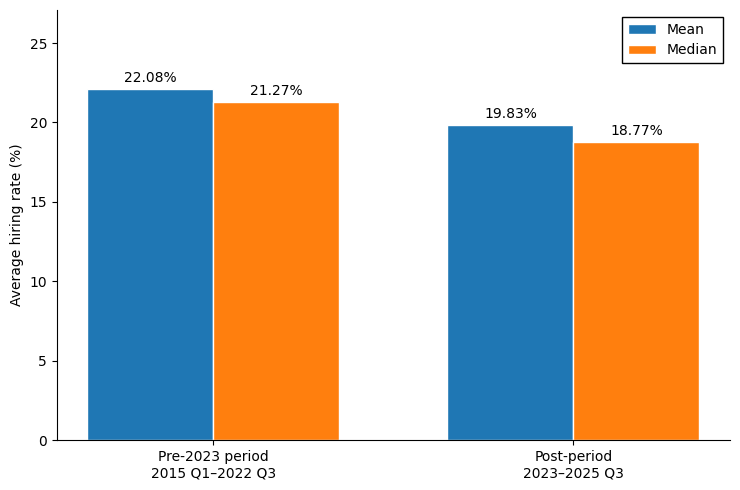

**Fig. 2. Mean and Median Early-Career Hiring Rates Declined After 2022.**

In [18]:
hiring_plot_data = pd.DataFrame(
    {
        "period": [
            "Pre-2023 period\n2015 Q1–2022 Q3",
            "Post-period\n2023–2025 Q3",
        ],
        "mean": [
            descriptive_group_data["pre_hiring_rate_pct"].mean(),
            descriptive_group_data["post_hiring_rate_pct"].mean(),
        ],
        "median": [
            descriptive_group_data["pre_hiring_rate_pct"].median(),
            descriptive_group_data["post_hiring_rate_pct"].median(),
        ],
    }
)

x_positions = np.arange(len(hiring_plot_data))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(7.5, 5))

mean_bars = ax.bar(
    x_positions - bar_width / 2,
    hiring_plot_data["mean"],
    bar_width,
    color="tab:blue",
    edgecolor="white",
    label="Mean",
)

median_bars = ax.bar(
    x_positions + bar_width / 2,
    hiring_plot_data["median"],
    bar_width,
    color="tab:orange",
    edgecolor="white",
    label="Median",
)

ax.bar_label(
    mean_bars,
    labels=[
        f"{value:.2f}%"
        for value in hiring_plot_data["mean"]
    ],
    padding=3,
)

ax.bar_label(
    median_bars,
    labels=[
        f"{value:.2f}%"
        for value in hiring_plot_data["median"]
    ],
    padding=3,
)

ax.set_ylabel("Average hiring rate (%)")
ax.set_xticks(
    x_positions,
    hiring_plot_data["period"],
)
ax.set_ylim(
    0,
    hiring_plot_data["mean"].max() + 5,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

descriptive_figure_path = (
    project_root
    / "figures"
    / "early_career_hiring_pre_post.png"
)
descriptive_figure_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)
fig.savefig(
    descriptive_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 2. Mean and Median Early-Career Hiring Rates Declined After 2022.**"
    )
)

Across the 3,719 state-industry groups, the mean early-career hiring rate declined from 22.08% during 2015 Q1–2022 Q3 to 19.83% during 2023 Q1–2025 Q3. The median also declined from 21.27% to 18.77%, showing that the overall decrease was not driven only by unusually large hiring rates. Quarterly rates are first averaged within each group, giving every group equal weight in each period, and 2022 Q4 is excluded as a transition quarter. This is an unadjusted descriptive comparison and does not establish that AI exposure caused the decline.

### AI Exposure and the Change in Early-Career Hiring

Because AI exposure varies at the industry level, I average the state-industry hiring-rate changes within each industry before plotting the relationship. Each point therefore represents one of the 81 industries, and each industry receives equal weight. The fitted line summarizes the unadjusted association and is not a causal estimate.

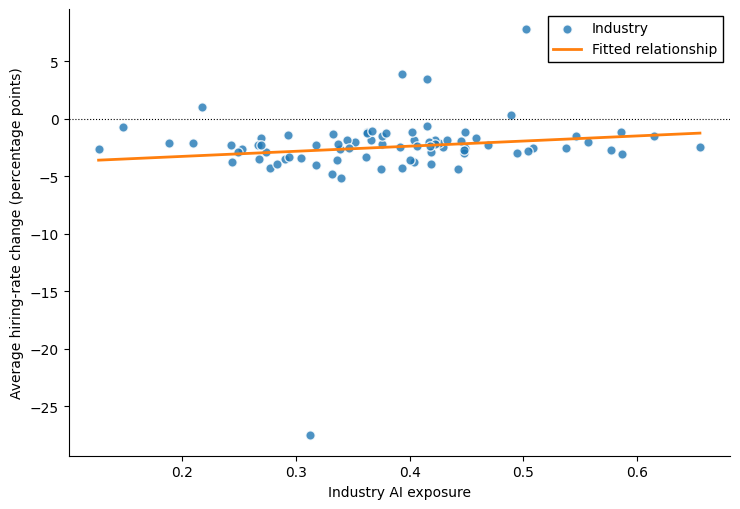

**Fig. 3. AI Exposure Shows Little Unadjusted Relationship with Early-Career Hiring Changes.**

Pearson correlation: 0.14
Spearman correlation: 0.169


,industry,industry_name,ai_exposure,average_hiring_change_pct_points,states
0,482,Rail Transportation,0.312605,-27.522778,3
1,561,Administrative and Support Services,0.339508,-5.151008,49
2,111,Crop Production,0.331394,-4.764707,48
3,211,Oil and Gas Extraction,0.502061,7.798445,24
4,487,Scenic and Sightseeing Transportation,0.393267,3.936168,43
5,486,Pipeline Transportation,0.415528,3.519550,35


In [20]:
# Create one observation per industry
industry_names = (
    primary_analysis_panel[
        ["industry", "industry_name"]
    ]
    .drop_duplicates("industry")
)

industry_descriptive_data = (
    descriptive_group_data
    .groupby("industry", as_index=False)
    .agg(
        ai_exposure=("ai_exposure", "first"),
        average_hiring_change_pct_points=(
            "hiring_change_pct_points",
            "mean",
        ),
        median_hiring_change_pct_points=(
            "hiring_change_pct_points",
            "median",
        ),
        states=("state", "nunique"),
    )
    .merge(
        industry_names,
        on="industry",
        how="left",
        validate="one_to_one",
    )
)

expected_industries = primary_analysis_panel["industry"].nunique()
assert len(industry_descriptive_data) == expected_industries


# Summarize the unadjusted association
pearson_correlation = industry_descriptive_data[
    "ai_exposure"
].corr(
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ]
)

spearman_correlation = industry_descriptive_data[
    "ai_exposure"
].corr(
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    method="spearman",
)

line_slope, line_intercept = np.polyfit(
    industry_descriptive_data["ai_exposure"],
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    1,
)

line_x = np.linspace(
    industry_descriptive_data["ai_exposure"].min(),
    industry_descriptive_data["ai_exposure"].max(),
    100,
)
line_y = line_intercept + line_slope * line_x


# Plot the industry-level relationship
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.scatter(
    industry_descriptive_data["ai_exposure"],
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    color="tab:blue",
    edgecolor="white",
    alpha=0.8,
    s=45,
    label="Industry",
)

ax.plot(
    line_x,
    line_y,
    color="tab:orange",
    linewidth=2,
    label="Fitted relationship",
)

ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=0.8,
)

ax.set_xlabel("Industry AI exposure")
ax.set_ylabel("Average hiring-rate change (percentage points)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

ai_hiring_figure_path = (
    project_root
    / "figures"
    / "ai_exposure_hiring_change.png"
)
fig.savefig(
    ai_hiring_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 3. AI Exposure Shows Little Unadjusted Relationship with Early-Career Hiring Changes.**"
    )
)

print(
    "Pearson correlation:",
    round(pearson_correlation, 3),
)
print(
    "Spearman correlation:",
    round(spearman_correlation, 3),
)

industry_change_extremes = pd.concat(
    [
        industry_descriptive_data.nsmallest(
            3,
            "average_hiring_change_pct_points",
        ),
        industry_descriptive_data.nlargest(
            3,
            "average_hiring_change_pct_points",
        ),
    ],
    ignore_index=True,
)

display(
    industry_change_extremes[
        [
            "industry",
            "industry_name",
            "ai_exposure",
            "average_hiring_change_pct_points",
            "states",
        ]
    ]
)

Across the 81 industries, AI exposure had only a weak positive association with the average pre-to-post change in early-career hiring. The Pearson correlation was 0.140 and the Spearman correlation was 0.169. The unadjusted comparison therefore did not show the expected pattern of more AI-exposed industries experiencing larger hiring declines. This does not establish that AI exposure has no relationship with hiring because the comparison does not account for employment adjustment, state differences, common quarterly changes, or the unequal number of states observed within each industry.

### Employment Above Trend and the Change in Early-Career Hiring

Both employment above trend and hiring-rate changes vary at the state-industry level, so this comparison uses all 3,719 eligible groups. Because both variables contain a small number of extreme values, the graph displays the 3,579 observations within their 1st–99th percentile bounds. The full sample remains unchanged and is included in the influence comparison that follows.

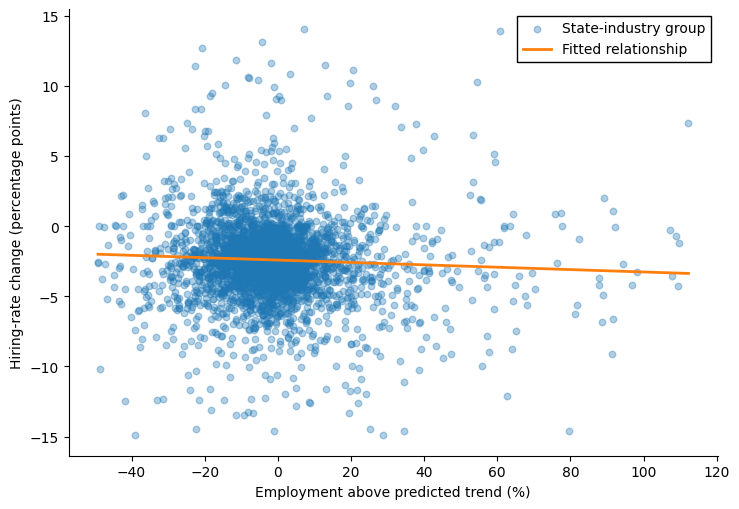

**Fig. 4. Employment Above Trend Shows Little Relationship with Early-Career Hiring Changes.**

Groups in full sample: 3719
Groups displayed: 3579


In [21]:
# Identify the central range for a readable figure
trend_bounds = descriptive_group_data[
    "employment_above_trend_log_pct"
].quantile([0.01, 0.99])

hiring_change_bounds = descriptive_group_data[
    "hiring_change_pct_points"
].quantile([0.01, 0.99])

central_trend_data = descriptive_group_data.loc[
    descriptive_group_data[
        "employment_above_trend_log_pct"
    ].between(trend_bounds.iloc[0], trend_bounds.iloc[1])
    & descriptive_group_data[
        "hiring_change_pct_points"
    ].between(
        hiring_change_bounds.iloc[0],
        hiring_change_bounds.iloc[1],
    )
].copy()

trend_line_slope, trend_line_intercept = np.polyfit(
    central_trend_data["employment_above_trend_log_pct"],
    central_trend_data["hiring_change_pct_points"],
    1,
)

trend_line_x = np.linspace(
    central_trend_data["employment_above_trend_log_pct"].min(),
    central_trend_data["employment_above_trend_log_pct"].max(),
    100,
)
trend_line_y = (
    trend_line_intercept
    + trend_line_slope * trend_line_x
)


# Plot the central observations
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.scatter(
    central_trend_data["employment_above_trend_log_pct"],
    central_trend_data["hiring_change_pct_points"],
    color="tab:blue",
    alpha=0.35,
    s=22,
    label="State-industry group",
)

ax.plot(
    trend_line_x,
    trend_line_y,
    color="tab:orange",
    linewidth=2,
    label="Fitted relationship",
)

ax.set_xlabel("Employment above predicted trend (%)")
ax.set_ylabel("Hiring-rate change (percentage points)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

trend_hiring_figure_path = (
    project_root
    / "figures"
    / "employment_trend_hiring_change.png"
)
fig.savefig(
    trend_hiring_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 4. Employment Above Trend Shows Little Relationship with Early-Career Hiring Changes.**"
    )
)

print("Groups in full sample:", len(descriptive_group_data))
print("Groups displayed:", len(central_trend_data))

### Check the Influence of Extreme Observations

I compare Pearson and Spearman correlations in the full samples with correlations calculated within the 1st–99th percentile bounds. This is a diagnostic only: observations outside these bounds remain in the primary dataset and will be addressed later through regression sensitivity checks.

In [22]:
# Apply the same percentile diagnostic to the industry relationship
ai_exposure_bounds = industry_descriptive_data[
    "ai_exposure"
].quantile([0.01, 0.99])

industry_change_bounds = industry_descriptive_data[
    "average_hiring_change_pct_points"
].quantile([0.01, 0.99])

central_ai_data = industry_descriptive_data.loc[
    industry_descriptive_data["ai_exposure"].between(
        ai_exposure_bounds.iloc[0],
        ai_exposure_bounds.iloc[1],
    )
    & industry_descriptive_data[
        "average_hiring_change_pct_points"
    ].between(
        industry_change_bounds.iloc[0],
        industry_change_bounds.iloc[1],
    )
].copy()


def association_summary(relationship, sample, data, x, y):
    return {
        "relationship": relationship,
        "sample": sample,
        "observations": len(data),
        "pearson_correlation": data[x].corr(data[y]),
        "spearman_correlation": data[x].corr(
            data[y],
            method="spearman",
        ),
    }


influence_comparison = pd.DataFrame(
    [
        association_summary(
            "AI exposure and hiring change",
            "Full sample",
            industry_descriptive_data,
            "ai_exposure",
            "average_hiring_change_pct_points",
        ),
        association_summary(
            "AI exposure and hiring change",
            "1st–99th percentile bounds",
            central_ai_data,
            "ai_exposure",
            "average_hiring_change_pct_points",
        ),
        association_summary(
            "Employment trend and hiring change",
            "Full sample",
            descriptive_group_data,
            "employment_above_trend_log_pct",
            "hiring_change_pct_points",
        ),
        association_summary(
            "Employment trend and hiring change",
            "1st–99th percentile bounds",
            central_trend_data,
            "employment_above_trend_log_pct",
            "hiring_change_pct_points",
        ),
    ]
)

display(influence_comparison.round(3))

,relationship,sample,observations,pearson_correlation,spearman_correlation
0,AI exposure and hiring change,Full sample,81,0.140,0.169
1,AI exposure and hiring change,1st–99th percentile bounds,77,0.089,0.131
2,Employment trend and hiring change,Full sample,3719,0.025,-0.059
3,Employment trend and hiring change,1st–99th percentile bounds,3579,-0.051,-0.061


Employment above trend had little unadjusted relationship with hiring-rate changes. Its Pearson correlation with hiring change was 0.025 in the full sample and -0.051 within the percentile bounds; the corresponding Spearman correlations were -0.059 and -0.061. The change in the Pearson direction shows that extreme values influenced the fitted linear relationship, but every correlation remained close to zero.

The AI-exposure relationship was also sensitive to extremes but remained weak. Its Pearson correlation declined from 0.140 to 0.089, while its Spearman correlation declined from 0.169 to 0.131. The descriptive evidence therefore did not show a strong relationship between either explanatory measure and hiring changes. All observations remain in the primary sample; the percentile restrictions will be used only as a sensitivity check during modeling.

## Fixed-Effects Panel Analysis

The primary analysis asks whether the change in early-career hiring after 2022 differs with industry AI exposure after accounting for employment above trend. State-industry fixed effects control for stable differences across groups, while quarter fixed effects control for shocks shared across groups in the same quarter, including the pandemic and national labor-market conditions. Standard errors are clustered by industry because AI exposure varies at the industry level.

AI exposure and employment above trend do not change over time within a state-industry group, so their separate levels are absorbed by the state-industry fixed effects. The model therefore uses each measure's interaction with the post-period indicator. The estimates describe associations and are not interpreted as causal effects.

### Prepare the Model Variables

I rescale AI exposure so that its coefficient represents a 0.10 increase in exposure. I also rescale employment above trend so that its coefficient represents a 10-percentage-point increase. This changes only the units of the coefficients, not the estimated relationships.

In [23]:
# Prepare identifiers and readable coefficient units
model_data = primary_analysis_panel.copy()
model_data["state_industry"] = (
    model_data["state"].astype(str)
    + "_"
    + model_data["industry"].astype(str)
)
model_data["ai_exposure_10pp"] = model_data["ai_exposure"] / 0.10
model_data["employment_above_trend_10pp"] = (
    model_data["employment_above_trend_log_pct"] / 10
)

# Create the post-period interactions
model_data["ai_exposure_post"] = (
    model_data["ai_exposure_10pp"] * model_data["post"]
)
model_data["employment_trend_post"] = (
    model_data["employment_above_trend_10pp"]
    * model_data["post"]
)

# Confirm the estimation sample
model_columns = [
    "hiring_rate_pct",
    "ai_exposure_post",
    "employment_trend_post",
    "state_industry",
    "period",
    "industry",
]

assert model_data[model_columns].notna().all().all()
assert model_data["post"].isin([0, 1]).all()
assert not model_data.duplicated(
    ["state_industry", "period"]
).any()
assert model_data.groupby("state_industry")["post"].nunique().eq(2).all()

print("Observations:", f"{len(model_data):,}")
print("State-industry groups:", f"{model_data['state_industry'].nunique():,}")
print("Quarters:", model_data["period"].nunique())
print("Industry clusters:", model_data["industry"].nunique())

Observations: 148,053
State-industry groups: 3,719
Quarters: 42
Industry clusters: 81


### Estimate the Primary Models

The first model estimates the post-period AI-exposure relationship without the employment adjustment measure. The second is the primary specification and adds employment above trend. Comparing the AI coefficient across the two models shows whether accounting for post-pandemic employment adjustment materially changes the estimated relationship. Both models use the same fixed effects and industry-clustered standard errors.

In [24]:
# Model 1: AI exposure interaction only
ai_only_model = cast(
    Feols,
    feols(
        "hiring_rate_pct ~ ai_exposure_post | state_industry + period",
        data=model_data,
        vcov={"CRV1": "industry"},
    ),
)

# Model 2: primary specification with employment adjustment
primary_model = cast(
    Feols,
    feols(
        (
            "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=model_data,
        vcov={"CRV1": "industry"},
    ),
)

# Display the estimated coefficients and uncertainty
def tidy_model_results(model: Feols, model_name: str) -> pd.DataFrame:
    results = model.tidy().rename_axis("term").reset_index()
    results.insert(0, "model", model_name)
    return results


model_results = pd.concat(
    [
        tidy_model_results(ai_only_model, "AI exposure only"),
        tidy_model_results(primary_model, "Primary model"),
    ],
    ignore_index=True,
)

display(model_results.round(3))

,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
0,AI exposure only,ai_exposure_post,0.090,0.112,0.805,0.423,-0.133,0.314
1,Primary model,ai_exposure_post,0.102,0.113,0.903,0.369,-0.123,0.327
2,Primary model,employment_trend_post,-0.032,0.046,-0.684,0.496,-0.124,0.061


Model 1 estimates the relationship between AI exposure and the post-2022 change in early-career hiring without including employment above trend. The AI-exposure coefficient is 0.090, meaning that a 0.10 increase in AI exposure is associated with a 0.090-percentage-point increase in the hiring rate after 2022. However, the standard error is 0.112, the p-value is 0.423, and the 95% confidence interval ranges from −0.133 to 0.314 percentage points. Because the confidence interval contains zero and the p-value is large, Model 1 does not provide statistically clear evidence of a relationship between AI exposure and the change in hiring.

Model 2 adds employment above the pre-COVID trend. After including this measure, the AI-exposure coefficient increases slightly from 0.090 to 0.102. This means that a 0.10 increase in AI exposure is associated with an estimated 0.102-percentage-point increase in the post-2022 hiring rate. The estimate remains statistically insignificant, with a standard error of 0.113, a p-value of 0.369, and a 95% confidence interval from −0.123 to 0.327 percentage points.

The employment-above-trend coefficient is −0.032. This means that employment being 10 percentage points further above its predicted trend is associated with a 0.032-percentage-point lower hiring rate after 2022. This relationship is also not statistically significant: its p-value is 0.496, and its confidence interval ranges from −0.124 to 0.061 percentage points.

Overall, adding employment above trend does not meaningfully change the AI-exposure estimate. The AI coefficient remains small, slightly positive, and statistically uncertain in both models. Therefore, these results do not support the expectation that industries with greater AI exposure experienced a larger decline in early-career hiring rates after 2022. They also do not show a clear relationship between employment above trend and subsequent hiring rates. These estimates should be interpreted as a lack of statistically clear evidence, rather than proof that the relationships are exactly zero.

### Check the Primary Model

Before interpreting the secondary outcome, I check whether the primary model has unusual fitted values, unequal residual spread, or extreme residuals. The residual-versus-fitted plot examines whether the errors remain centered near zero and whether their spread changes with the predicted hiring rate. The Q-Q plot compares the residual distribution with a normal distribution. These plots are diagnostics rather than tests of statistical significance, and perfectly normal residuals are not required for the industry-clustered inference used here.

,diagnostic,value
0,Mean residual,0.000
1,Residual standard deviation,8.072
2,Residual skewness,2.670
3,Residual excess kurtosis,37.191
4,99th percentile of absolute residuals,30.770
5,Absolute residuals above 50 percentage points,369.000
6,Negative fitted hiring rates,158.000


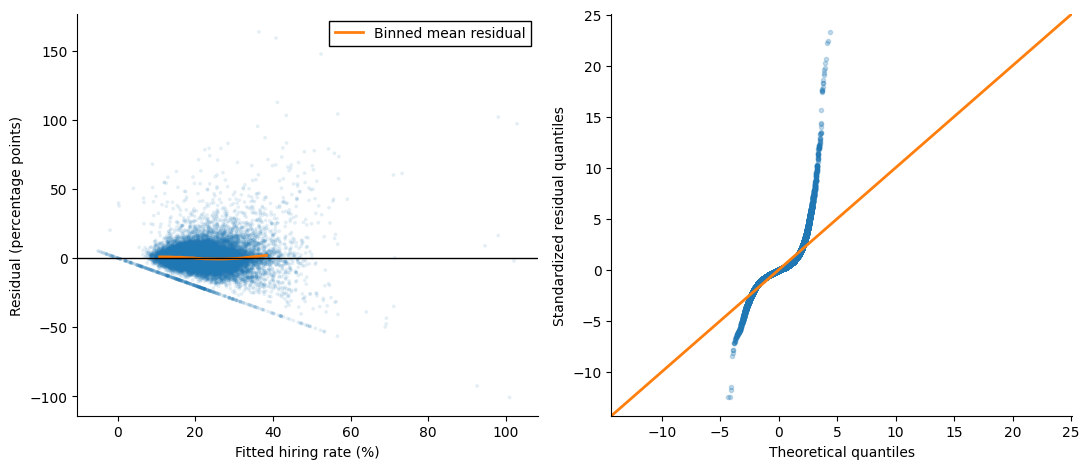

**Fig. 5. Primary-Model Residuals Show Heavy Tails and Increasing Spread.**

In [25]:
# Collect fitted values and residuals
primary_diagnostics = pd.DataFrame(
    {
        "fitted": primary_model.predict(),
        "residual": primary_model.resid(),
    },
    index=model_data.index,
)
primary_diagnostics["absolute_residual"] = (
    primary_diagnostics["residual"].abs()
)

residual_summary = pd.Series(
    {
        "Mean residual": primary_diagnostics["residual"].mean(),
        "Residual standard deviation": primary_diagnostics["residual"].std(),
        "Residual skewness": primary_diagnostics["residual"].skew(),
        "Residual excess kurtosis": primary_diagnostics["residual"].kurt(),
        "99th percentile of absolute residuals": primary_diagnostics["absolute_residual"].quantile(0.99),
        "Absolute residuals above 50 percentage points": primary_diagnostics["absolute_residual"].gt(50).sum(),
        "Negative fitted hiring rates": primary_diagnostics["fitted"].lt(0).sum(),
    },
    name="value",
).rename_axis("diagnostic").reset_index()

display(residual_summary.round(3))

# Calculate the mean residual across fitted-value bins
primary_diagnostics["fitted_bin"] = pd.qcut(
    primary_diagnostics["fitted"],
    20,
    duplicates="drop",
)
binned_residuals = (
    primary_diagnostics
    .groupby("fitted_bin", observed=True)
    .agg(
        fitted_mean=("fitted", "mean"),
        residual_mean=("residual", "mean"),
    )
    .reset_index(drop=True)
)

# Sample points only for a readable scatter plot
diagnostic_sample = primary_diagnostics.sample(
    n=min(30_000, len(primary_diagnostics)),
    random_state=401,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

axes[0].scatter(
    diagnostic_sample["fitted"],
    diagnostic_sample["residual"],
    color="tab:blue",
    s=7,
    alpha=0.12,
    edgecolors="none",
    rasterized=True,
)
axes[0].plot(
    binned_residuals["fitted_mean"],
    binned_residuals["residual_mean"],
    color="tab:orange",
    linewidth=2,
    label="Binned mean residual",
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted hiring rate (%)")
axes[0].set_ylabel("Residual (percentage points)")
axes[0].legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

qqplot(
    primary_diagnostics["residual"],
    line="45",
    fit=True,
    ax=axes[1],
    marker=".",
    markerfacecolor="tab:blue",
    markeredgecolor="tab:blue",
    alpha=0.25,
)
axes[1].get_lines()[1].set_color("tab:orange")
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Standardized residual quantiles")

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

fig.tight_layout()

diagnostic_figure_path = (
    project_root / "figures" / "primary_model_diagnostics.png"
)
fig.savefig(
    diagnostic_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 5. Primary-Model Residuals Show Heavy Tails and Increasing Spread.**"
    )
)

The residual-versus-fitted plot shows that the errors remain reasonably close to zero through most of the fitted range, although the spread becomes wider for groups with higher predicted hiring rates. The binned mean residual stays within approximately two percentage points of zero, suggesting only modest systematic curvature. The linear model produces 158 negative fitted rates, representing about 0.1% of the sample, so invalid predictions are rare rather than a general model problem.

The Q-Q plot is expected to depart from the reference line in the tails. The residual skewness is 2.670 and excess kurtosis is 37.191, while 369 observations have absolute residuals greater than 50 percentage points. This reflects the small state-industry cells that can have unusually high published hiring rates. The heavy tails and unequal spread justify the use of cluster-robust standard errors, but they also make an outlier-sensitivity check important. The Q-Q plot does not determine whether the AI coefficient is statistically significant and does not replace the later event-study assessment of pre-existing trends.

### Check Sensitivity to Extreme Observations

I re-estimate the primary model after excluding the largest 1% of absolute residuals and, separately, observations outside the 1st-99th percentile range of the employment-above-trend measure. These restrictions are diagnostic checks only; the full published sample remains the primary specification.

In [26]:
# Exclude the largest 1% of absolute residuals
absolute_residual_cutoff = primary_diagnostics[
    "absolute_residual"
].quantile(0.99)
central_residual_data = model_data.loc[
    primary_diagnostics["absolute_residual"].le(
        absolute_residual_cutoff
    )
].copy()

residual_sensitivity_model = cast(
    Feols,
    feols(
        (
            "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=central_residual_data,
        vcov={"CRV1": "industry"},
    ),
)

# Exclude the tails of the employment-trend measure
employment_trend_bounds = model_data[
    "employment_above_trend_log_pct"
].quantile([0.01, 0.99])
central_employment_trend_data = model_data.loc[
    model_data["employment_above_trend_log_pct"].between(
        employment_trend_bounds.iloc[0],
        employment_trend_bounds.iloc[1],
    )
].copy()

employment_trend_sensitivity_model = cast(
    Feols,
    feols(
        (
            "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=central_employment_trend_data,
        vcov={"CRV1": "industry"},
    ),
)

outlier_sensitivity_results = pd.concat(
    [
        tidy_model_results(primary_model, "Full primary sample"),
        tidy_model_results(
            residual_sensitivity_model,
            "Exclude largest 1% of residuals",
        ),
        tidy_model_results(
            employment_trend_sensitivity_model,
            "Exclude employment-trend tails",
        ),
    ],
    ignore_index=True,
)

display(outlier_sensitivity_results.round(3))

/Users/minhvietnguyen/Documents/Fall_26/DA 401/senior-research/.venv/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 3 singleton fixed effect(s) dropped from the model.
  warnings.warn(


,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
0,Full primary sample,ai_exposure_post,0.102,0.113,0.903,0.369,-0.123,0.327
1,Full primary sample,employment_trend_post,-0.032,0.046,-0.684,0.496,-0.124,0.061
2,Exclude largest 1% of residuals,ai_exposure_post,0.053,0.111,0.480,0.632,-0.167,0.274
3,Exclude largest 1% of residuals,employment_trend_post,-0.035,0.037,-0.928,0.356,-0.109,0.040
4,Exclude employment-trend tails,ai_exposure_post,0.118,0.113,1.045,0.299,-0.107,0.344
5,Exclude employment-trend tails,employment_trend_post,-0.123,0.061,-2.027,0.046,-0.244,-0.002


The AI-exposure estimate decreases from 0.102 in the full sample to 0.053 after excluding the largest 1% of absolute residuals, but it remains statistically insignificant (`p = 0.632`). Excluding the tails of the employment-above-trend measure produces an AI estimate of 0.118, which is also insignificant (`p = 0.299`). Across all three specifications, there is no statistically clear relationship between AI exposure and the post-2022 change in the early-career hiring rate.

The employment-above-trend interaction remains statistically insignificant after excluding the largest residuals. After excluding the tails of the employment-trend measure, however, its estimate becomes −0.123 percentage points and is just statistically significant at the 5% level (`p = 0.046`). Because this result appears only under one sample restriction and is close to the threshold, the employment-adjustment estimate should be described as sensitive to tail handling rather than robust evidence of a relationship.

### Secondary Outcome: Number of Hires

The primary outcome remains the hiring rate. As a secondary analysis, I estimate the same fixed-effects specification using the natural logarithm of `HirAEnd`, the number of hires that remain employed at the end of the quarter. This distinguishes a change in hiring activity from a change in the rate caused by a changing employment denominator.

A regular logarithm is undefined for zero counts, so this model uses observations with at least one hire and reports the number excluded. State-industry groups with only one positive-count observation are also removed because they cannot contribute within-group variation. The AI coefficient is converted to a percentage change associated with a 0.10 increase in exposure. The model retains the employment-above-trend interaction, state-industry fixed effects, quarter fixed effects, and industry-clustered standard errors.

In [27]:
# Keep positive hire counts for the logarithmic outcome
assert model_data["hire_count"].notna().all()
positive_hire_count_data = model_data.loc[
    model_data["hire_count"].gt(0)
].copy()
positive_hire_count_data["log_hire_count"] = np.log(
    positive_hire_count_data["hire_count"]
)
positive_observations_by_group = (
    positive_hire_count_data
    .groupby("state_industry")["log_hire_count"]
    .transform("size")
)
hire_count_model_data = positive_hire_count_data.loc[
    positive_observations_by_group.gt(1)
].copy()

print("Primary-panel observations:", f"{len(model_data):,}")
print(
    "Zero hire-count observations excluded:",
    f"{model_data['hire_count'].eq(0).sum():,}",
)
print(
    "Singleton observations excluded:",
    f"{positive_observations_by_group.eq(1).sum():,}",
)
print("Model observations:", f"{len(hire_count_model_data):,}")

# Estimate the secondary-outcome model
secondary_hire_model = cast(
    Feols,
    feols(
        (
            "log_hire_count ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=hire_count_model_data,
        vcov={"CRV1": "industry"},
    ),
)

secondary_hire_results = tidy_model_results(
    secondary_hire_model,
    "Secondary hire-count model",
)
secondary_hire_results["percent_change"] = (
    np.expm1(secondary_hire_results["Estimate"]) * 100
)

display(secondary_hire_results.round(3))

Primary-panel observations: 148,053
Zero hire-count observations excluded: 2,333
Singleton observations excluded: 14
Model observations: 145,706


,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,percent_change
0,Secondary hire-count model,ai_exposure_post,-0.033,0.018,-1.821,0.072,-0.069,0.003,-3.229
1,Secondary hire-count model,employment_trend_post,0.015,0.010,1.474,0.145,-0.005,0.034,1.464


### Check the Secondary Outcome Model

I apply the same residual checks to the log-hire-count model. The residual-versus-fitted plot checks whether the errors remain centered near zero and whether their spread changes across predicted hiring levels. The Q-Q plot checks for skewness and heavy tails. I then re-estimate the model after excluding its largest 1% of absolute residuals and with `log(1 + hires)`, which retains the zero-hire observations. These are sensitivity checks; the positive-count log model remains the secondary specification.

,diagnostic,value
0,Mean residual,0.000
1,Residual standard deviation,0.325
2,Residual skewness,-0.176
3,Residual excess kurtosis,3.506
4,99th percentile of absolute residuals,1.065
5,Maximum absolute residual,3.382


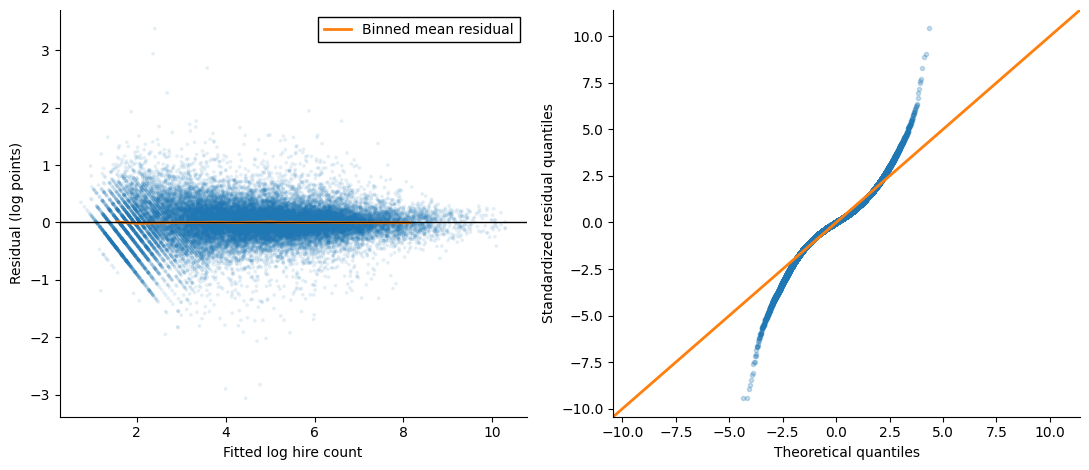

**Fig. 6. The Log-Hire-Count Model Reduces Skewness but Retains Unequal Residual Spread.**

In [28]:
# Collect fitted values and residuals
secondary_diagnostics = pd.DataFrame(
    {
        "fitted": secondary_hire_model.predict(),
        "residual": secondary_hire_model.resid(),
    },
    index=hire_count_model_data.index,
)
secondary_diagnostics["absolute_residual"] = (
    secondary_diagnostics["residual"].abs()
)

secondary_residual_summary = pd.Series(
    {
        "Mean residual": secondary_diagnostics["residual"].mean(),
        "Residual standard deviation": secondary_diagnostics["residual"].std(),
        "Residual skewness": secondary_diagnostics["residual"].skew(),
        "Residual excess kurtosis": secondary_diagnostics["residual"].kurt(),
        "99th percentile of absolute residuals": secondary_diagnostics["absolute_residual"].quantile(0.99),
        "Maximum absolute residual": secondary_diagnostics["absolute_residual"].max(),
    },
    name="value",
).rename_axis("diagnostic").reset_index()

display(secondary_residual_summary.round(3))

# Calculate mean residuals across fitted-value bins
secondary_diagnostics["fitted_bin"] = pd.qcut(
    secondary_diagnostics["fitted"],
    20,
    duplicates="drop",
)
secondary_binned_residuals = (
    secondary_diagnostics
    .groupby("fitted_bin", observed=True)
    .agg(
        fitted_mean=("fitted", "mean"),
        residual_mean=("residual", "mean"),
    )
    .reset_index(drop=True)
)
secondary_diagnostic_sample = secondary_diagnostics.sample(
    n=min(30_000, len(secondary_diagnostics)),
    random_state=401,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

axes[0].scatter(
    secondary_diagnostic_sample["fitted"],
    secondary_diagnostic_sample["residual"],
    color="tab:blue",
    s=7,
    alpha=0.12,
    edgecolors="none",
    rasterized=True,
)
axes[0].plot(
    secondary_binned_residuals["fitted_mean"],
    secondary_binned_residuals["residual_mean"],
    color="tab:orange",
    linewidth=2,
    label="Binned mean residual",
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted log hire count")
axes[0].set_ylabel("Residual (log points)")
axes[0].legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

qqplot(
    secondary_diagnostics["residual"],
    line="45",
    fit=True,
    ax=axes[1],
    marker=".",
    markerfacecolor="tab:blue",
    markeredgecolor="tab:blue",
    alpha=0.25,
)
axes[1].get_lines()[1].set_color("tab:orange")
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Standardized residual quantiles")

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

fig.tight_layout()

secondary_diagnostic_figure_path = (
    project_root / "figures" / "secondary_hire_model_diagnostics.png"
)
fig.savefig(
    secondary_diagnostic_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 6. The Log-Hire-Count Model Reduces Skewness but Retains Unequal Residual Spread.**"
    )
)

In [29]:
# Exclude the largest 1% of absolute residuals
secondary_residual_cutoff = secondary_diagnostics[
    "absolute_residual"
].quantile(0.99)
central_secondary_data = hire_count_model_data.loc[
    secondary_diagnostics["absolute_residual"].le(
        secondary_residual_cutoff
    )
].copy()

secondary_trimmed_model = cast(
    Feols,
    feols(
        (
            "log_hire_count ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=central_secondary_data,
        vcov={"CRV1": "industry"},
    ),
)

# Retain zero counts with log(1 + hires)
zero_inclusive_hire_data = model_data.copy()
zero_inclusive_hire_data["log1p_hire_count"] = np.log1p(
    zero_inclusive_hire_data["hire_count"]
)
secondary_log1p_model = cast(
    Feols,
    feols(
        (
            "log1p_hire_count ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period"
        ),
        data=zero_inclusive_hire_data,
        vcov={"CRV1": "industry"},
    ),
)

secondary_sensitivity_results = pd.concat(
    [
        tidy_model_results(
            secondary_hire_model,
            "Positive counts",
        ),
        tidy_model_results(
            secondary_trimmed_model,
            "Exclude largest 1% of residuals",
        ),
        tidy_model_results(
            secondary_log1p_model,
            "log(1 + hires), including zeros",
        ),
    ],
    ignore_index=True,
)
secondary_sensitivity_results["percent_change"] = (
    np.expm1(secondary_sensitivity_results["Estimate"]) * 100
)
secondary_sensitivity_results["ci_lower_pct"] = (
    np.expm1(secondary_sensitivity_results["2.5%"]) * 100
)
secondary_sensitivity_results["ci_upper_pct"] = (
    np.expm1(secondary_sensitivity_results["97.5%"]) * 100
)

display(
    secondary_sensitivity_results.loc[
        secondary_sensitivity_results["term"].eq(
            "ai_exposure_post"
        ),
        [
            "model",
            "percent_change",
            "ci_lower_pct",
            "ci_upper_pct",
            "Pr(>|t|)",
        ],
    ].round(3)
)

,model,percent_change,ci_lower_pct,ci_upper_pct,Pr(>|t|)
0,Positive counts,-3.229,-6.639,0.305,0.072
2,Exclude largest 1% of residuals,-3.136,-6.181,0.008,0.051
4,"log(1 + hires), including zeros",-2.851,-6.180,0.596,0.103


The log transformation substantially improves the secondary model's residual distribution. Residual skewness is -0.176 and excess kurtosis is 3.506, compared with much stronger right skewness and heavier tails in the hiring-rate model. The residual spread is still larger among groups with lower predicted hire counts, so the industry-clustered standard errors remain important.

The estimated AI relationship is stable across the sensitivity checks. The main secondary specification estimates 3.23% fewer hires for a 0.10 increase in exposure (`p = 0.072`; 95% CI: -6.64% to 0.31%). Excluding the largest 1% of residuals gives an estimate of -3.14% (`p = 0.051`), while retaining zero counts with `log(1 + hires)` gives -2.85% (`p = 0.103`). Therefore, zero counts and extreme residuals do not explain the negative estimate. However, none of these overall estimates is statistically significant at the 5% level, so the secondary result should be described as suggestive rather than conclusive.

## Quarterly AI-Exposure Event Study

The primary models summarize the post-2022 period with one coefficient. To examine when the relationship changes, I interact AI exposure with each quarter and use 2022 Q3 as the reference period. Each quarterly coefficient represents the difference associated with a 0.10 increase in AI exposure relative to that reference quarter. The models retain the employment-above-trend adjustment, state-industry fixed effects, quarter fixed effects, and industry-clustered standard errors.

I estimate the quarterly specification for both the early-career hiring rate and the logarithm of the number of hires. The hiring-rate coefficients are measured in percentage points, while the logged hire-count coefficients are converted to percentage changes. The omitted 2022 Q4 transition quarter remains excluded. Because exposure is continuous and all industries are observed throughout the period, this figure describes dynamic associations rather than a causal event study.

In [30]:
event_reference_period = "2022Q3"
event_terms = (
    "i(period, ai_exposure_10pp, ref='2022Q3') "
    "+ employment_trend_post | state_industry + period"
)

# Estimate quarterly relationships for both outcomes
rate_event_model = cast(
    Feols,
    feols(
        f"hiring_rate_pct ~ {event_terms}",
        data=model_data,
        vcov={"CRV1": "industry"},
    ),
)

count_event_model = cast(
    Feols,
    feols(
        f"log_hire_count ~ {event_terms}",
        data=hire_count_model_data,
        vcov={"CRV1": "industry"},
    ),
)


def event_period_from_term(term):
    return term.split("::", maxsplit=1)[1].split(":", maxsplit=1)[0]


def tidy_event_results(model: Feols, outcome: str) -> pd.DataFrame:
    results = (
        model.tidy()
        .rename_axis("term")
        .reset_index()
        .rename(
            columns={
                "Estimate": "estimate",
                "Pr(>|t|)": "p_value",
                "2.5%": "ci_lower",
                "97.5%": "ci_upper",
            }
        )
    )
    results = results.loc[
        results["term"].str.startswith("period::"),
        ["term", "estimate", "p_value", "ci_lower", "ci_upper"],
    ].copy()
    results["period"] = results["term"].map(
        event_period_from_term
    )
    results["outcome"] = outcome

    reference_row = pd.DataFrame(
        {
            "term": ["Reference period"],
            "estimate": [0.0],
            "p_value": [np.nan],
            "ci_lower": [0.0],
            "ci_upper": [0.0],
            "period": [event_reference_period],
            "outcome": [outcome],
        }
    )

    return (
        pd.concat([results, reference_row], ignore_index=True)
        .sort_values("period")
        .reset_index(drop=True)
    )


rate_event_results = tidy_event_results(
    rate_event_model,
    "Hiring rate",
)
count_event_results = tidy_event_results(
    count_event_model,
    "Number of hires",
)

# Convert log coefficients and confidence limits to percentage changes
for column in ["estimate", "ci_lower", "ci_upper"]:
    count_event_results[column] = (
        np.expm1(count_event_results[column]) * 100
    )

event_study_results = pd.concat(
    [rate_event_results, count_event_results],
    ignore_index=True,
)

display(
    event_study_results.loc[
        event_study_results["period"].ge("2023Q1"),
        [
            "outcome",
            "period",
            "estimate",
            "ci_lower",
            "ci_upper",
            "p_value",
        ],
    ].round(3)
)

,outcome,period,estimate,ci_lower,ci_upper,p_value
31,Hiring rate,2023Q1,-1.216,-1.746,-0.687,0.000
32,Hiring rate,2023Q2,-0.944,-2.012,0.124,0.083
33,Hiring rate,2023Q3,-0.516,-0.885,-0.148,0.007
34,Hiring rate,2023Q4,-1.139,-1.922,-0.357,0.005
35,Hiring rate,2024Q1,-0.980,-1.513,-0.447,0.000
36,Hiring rate,2024Q2,-0.564,-1.501,0.374,0.235
37,Hiring rate,2024Q3,-0.063,-0.400,0.274,0.711
38,Hiring rate,2024Q4,-0.986,-1.608,-0.365,0.002
39,Hiring rate,2025Q1,-0.366,-0.877,0.146,0.159
40,Hiring rate,2025Q2,-0.204,-1.162,0.755,0.674


In [31]:
# Test whether all pre-reference coefficients equal zero
def joint_preperiod_test(model, outcome):
    coefficient_names = list(model.coef().index)
    preperiod_indices = [
        index
        for index, term in enumerate(coefficient_names)
        if term.startswith("period::")
        and event_period_from_term(term) < event_reference_period
    ]
    restrictions = np.eye(len(coefficient_names))[preperiod_indices]
    test = model.wald_test(
        R=restrictions,
        distribution="chi2",
    )

    return {
        "outcome": outcome,
        "preperiod_coefficients": len(preperiod_indices),
        "chi_square": test["statistic"],
        "p_value": test["pvalue"],
    }


preperiod_tests = pd.DataFrame(
    [
        joint_preperiod_test(rate_event_model, "Hiring rate"),
        joint_preperiod_test(count_event_model, "Number of hires"),
    ]
)

display(preperiod_tests.round(3))

,outcome,preperiod_coefficients,chi_square,p_value
0,Hiring rate,30,163.766,0.0
1,Number of hires,30,263.349,0.0


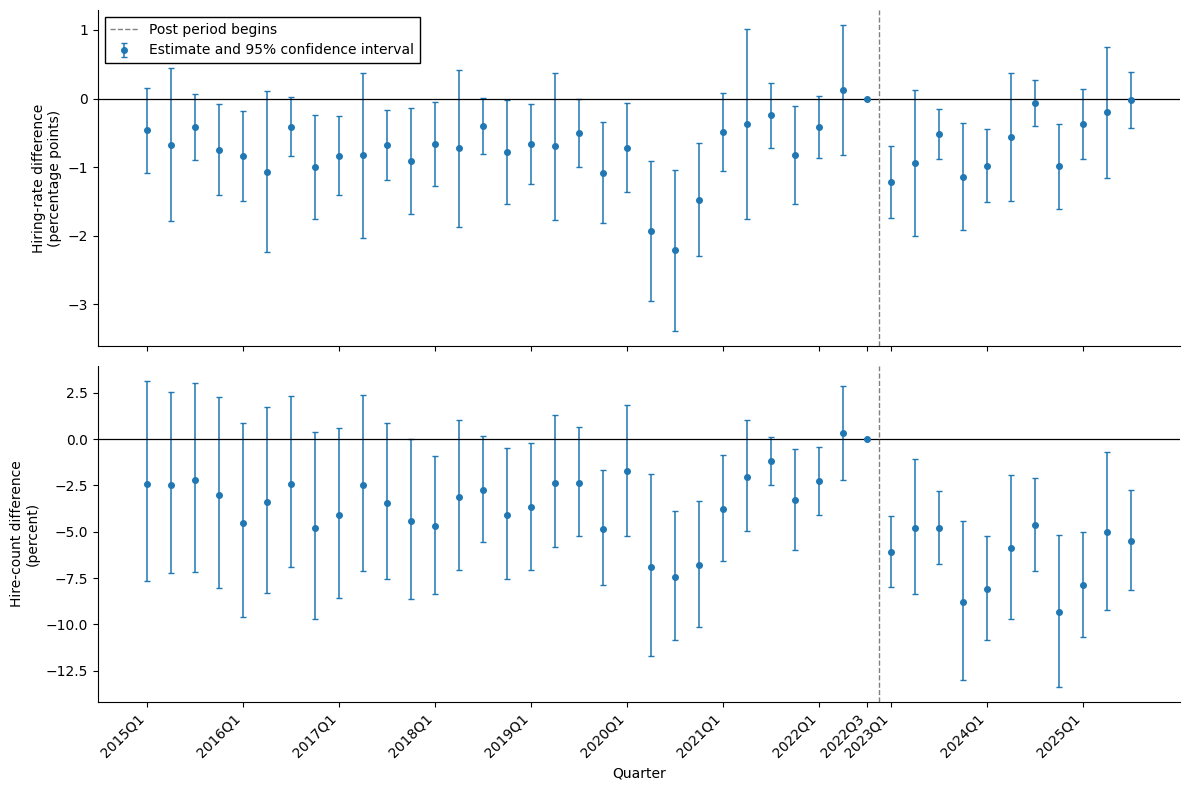

**Fig. 7. Post-2022 AI-Exposure Differences Fade for Hiring Rates but Persist for Hire Counts.**

In [32]:
event_period_order = sorted(model_data["period"].unique())
event_x_positions = {
    period: index
    for index, period in enumerate(event_period_order)
}
post_start_position = event_x_positions["2023Q1"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
)

plot_settings = [
    (
        axes[0],
        rate_event_results,
        "Hiring-rate difference\n(percentage points)",
    ),
    (
        axes[1],
        count_event_results,
        "Hire-count difference\n(percent)",
    ),
]

for axis, results, y_label in plot_settings:
    plot_data = (
        results.set_index("period")
        .loc[event_period_order]
        .reset_index()
    )
    x_values = plot_data["period"].map(event_x_positions)
    lower_errors = plot_data["estimate"] - plot_data["ci_lower"]
    upper_errors = plot_data["ci_upper"] - plot_data["estimate"]

    axis.errorbar(
        x_values,
        plot_data["estimate"],
        yerr=[lower_errors, upper_errors],
        fmt="o",
        color="tab:blue",
        ecolor="tab:blue",
        markersize=4,
        elinewidth=1.1,
        capsize=2,
        label="Estimate and 95% confidence interval",
    )
    axis.axhline(0, color="black", linewidth=0.9)
    axis.axvline(
        post_start_position - 0.5,
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Post period begins",
    )
    axis.set_ylabel(y_label)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

tick_periods = [
    period
    for period in event_period_order
    if period.endswith("Q1")
]
tick_periods.append(event_reference_period)
tick_periods = sorted(
    set(tick_periods),
    key=event_period_order.index,
)

axes[1].set_xticks(
    [event_x_positions[period] for period in tick_periods],
    tick_periods,
    rotation=45,
    ha="right",
)
axes[1].set_xlabel("Quarter")
axes[0].legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

event_study_figure_path = (
    project_root / "figures" / "ai_exposure_event_study.png"
)
fig.savefig(
    event_study_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 7. Post-2022 AI-Exposure Differences Fade for Hiring Rates but Persist for Hire Counts.**"
    )
)

Relative to 2022 Q3, a 0.10 increase in AI exposure is associated with a 1.21-percentage-point lower early-career hiring rate in 2023 Q1. The rate difference becomes smaller over time and is approximately zero by 2025 Q3. In contrast, the number of hires is approximately 6.1% lower in 2023 Q1 and remains about 5.5% lower in 2025 Q3. This suggests that the hiring-rate difference recovered while the difference in hiring volume persisted.

However, the pre-reference coefficients are jointly different from zero for both outcomes (`p < 0.001`). Several of the largest earlier differences occur during the pandemic. This means that more- and less-exposed industries were already following different hiring patterns before 2023, so the post-period estimates cannot be attributed only to generative AI. In addition, comparisons with one reference quarter may reflect industry-specific seasonality because the QWI series are not seasonally adjusted. The event-study results are therefore useful for showing timing, but they do not provide clean causal evidence. The seasonality checks below use industry-specific seasonal controls and balanced four-quarter windows.

## Industry Seasonality Sensitivity Check

The QWI series are not seasonally adjusted. Quarter fixed effects control for national changes in each period, but they do not remove stable seasonal patterns that differ across industries. For example, hiring may regularly rise in one quarter for hospitality but in a different quarter for another industry. If those patterns are related to AI exposure, part of the estimated post-period difference could reflect seasonality.

I use two checks. First, I add an industry-by-calendar-quarter fixed effect to the pooled hiring-rate and hire-count models. This absorbs each industry's usual Q1, Q2, Q3, and Q4 pattern. Second, I compare balanced four-quarter windows that each contain one observation from every calendar quarter. The original models remain the baseline specifications, while these checks show whether their conclusions are sensitive to industry seasonality.

### Add Industry-Specific Seasonal Fixed Effects

The following models add a fixed effect for each industry and calendar-quarter combination. The coefficient comparison focuses on whether the estimated AI-exposure relationship changes materially after removing stable industry-specific seasonality.

In [33]:
# Identify each industry's recurring calendar-quarter pattern
seasonal_model_data = model_data.copy()
seasonal_model_data["industry_season"] = (
    seasonal_model_data["industry"].astype(str)
    + "_Q"
    + seasonal_model_data["quarter"].astype(str)
)

seasonal_count_data = hire_count_model_data.copy()
seasonal_count_data["industry_season"] = (
    seasonal_count_data["industry"].astype(str)
    + "_Q"
    + seasonal_count_data["quarter"].astype(str)
)

# Re-estimate both outcomes with industry-specific seasonality
seasonal_rate_model = cast(
    Feols,
    feols(
        (
            "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period + industry_season"
        ),
        data=seasonal_model_data,
        vcov={"CRV1": "industry"},
    ),
)
seasonal_count_model = cast(
    Feols,
    feols(
        (
            "log_hire_count ~ ai_exposure_post + employment_trend_post "
            "| state_industry + period + industry_season"
        ),
        data=seasonal_count_data,
        vcov={"CRV1": "industry"},
    ),
)

# Compare baseline and seasonally adjusted estimates
pooled_seasonality_results = pd.concat(
    [
        tidy_model_results(primary_model, "Hiring rate: baseline")
        .assign(outcome="Hiring rate"),
        tidy_model_results(seasonal_rate_model, "Hiring rate: seasonal FE")
        .assign(outcome="Hiring rate"),
        tidy_model_results(secondary_hire_model, "Hire count: baseline")
        .assign(outcome="Number of hires"),
        tidy_model_results(seasonal_count_model, "Hire count: seasonal FE")
        .assign(outcome="Number of hires"),
    ],
    ignore_index=True,
)
pooled_seasonality_results["reported_effect"] = np.where(
    pooled_seasonality_results["outcome"].eq("Number of hires"),
    np.expm1(pooled_seasonality_results["Estimate"]) * 100,
    pooled_seasonality_results["Estimate"],
)
pooled_seasonality_results["effect_unit"] = np.where(
    pooled_seasonality_results["outcome"].eq("Number of hires"),
    "percent",
    "percentage points",
)
for source, target in [("2.5%", "ci_lower"), ("97.5%", "ci_upper")]:
    pooled_seasonality_results[target] = np.where(
        pooled_seasonality_results["outcome"].eq("Number of hires"),
        np.expm1(pooled_seasonality_results[source]) * 100,
        pooled_seasonality_results[source],
    )

display(
    pooled_seasonality_results[
        [
            "model",
            "term",
            "reported_effect",
            "effect_unit",
            "Pr(>|t|)",
            "ci_lower",
            "ci_upper",
        ]
    ].round(3)
)

/Users/minhvietnguyen/Documents/Fall_26/DA 401/senior-research/.venv/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(


,model,term,reported_effect,effect_unit,Pr(>|t|),ci_lower,ci_upper
0,Hiring rate: baseline,ai_exposure_post,0.102,percentage points,0.369,-0.123,0.327
1,Hiring rate: baseline,employment_trend_post,-0.032,percentage points,0.496,-0.124,0.061
2,Hiring rate: seasonal FE,ai_exposure_post,0.086,percentage points,0.456,-0.143,0.315
3,Hiring rate: seasonal FE,employment_trend_post,-0.024,percentage points,0.604,-0.114,0.067
4,Hire count: baseline,ai_exposure_post,-3.229,percent,0.072,-6.639,0.305
5,Hire count: baseline,employment_trend_post,1.464,percent,0.145,-0.508,3.476
6,Hire count: seasonal FE,ai_exposure_post,-3.326,percent,0.067,-6.771,0.247
7,Hire count: seasonal FE,employment_trend_post,1.508,percent,0.136,-0.479,3.534


### Compare Balanced Four-Quarter Windows

The broad pre-period contains many more quarters than the post-period, and the event study compares each quarter with 2022 Q3. To make the seasonal composition equal, I compare three windows: 2021 Q4–2022 Q3 as the immediate pre-period, 2023 Q1–2023 Q4 as the early post-period, and 2024 Q4–2025 Q3 as the latest post-period. Each window contains one Q1, Q2, Q3, and Q4. I retain only state-industry groups observed in all 12 selected quarters for each outcome.

In [34]:
balanced_windows = {
    "Immediate pre-period": ["2021Q4", "2022Q1", "2022Q2", "2022Q3"],
    "Early post-period": ["2023Q1", "2023Q2", "2023Q3", "2023Q4"],
    "Latest post-period": ["2024Q4", "2025Q1", "2025Q2", "2025Q3"],
}
period_to_window = {
    period: window
    for window, periods in balanced_windows.items()
    for period in periods
}
selected_periods = list(period_to_window)


def prepare_balanced_window_data(data):
    balanced = data.loc[data["period"].isin(selected_periods)].copy()
    complete_groups = (
        balanced.groupby("state_industry")["period"]
        .nunique()
        .loc[lambda counts: counts.eq(len(selected_periods))]
        .index
    )
    balanced = balanced.loc[
        balanced["state_industry"].isin(complete_groups)
    ].copy()
    balanced["comparison_window"] = balanced["period"].map(period_to_window)
    balanced["early_post"] = balanced["comparison_window"].eq(
        "Early post-period"
    ).astype(int)
    balanced["latest_post"] = balanced["comparison_window"].eq(
        "Latest post-period"
    ).astype(int)

    for window_name in ["early", "latest"]:
        indicator = balanced[f"{window_name}_post"]
        balanced[f"ai_exposure_{window_name}"] = (
            balanced["ai_exposure_10pp"] * indicator
        )
        balanced[f"employment_trend_{window_name}"] = (
            balanced["employment_above_trend_10pp"] * indicator
        )

    return balanced


balanced_rate_data = prepare_balanced_window_data(model_data)
balanced_count_data = prepare_balanced_window_data(hire_count_model_data)

balanced_terms = (
    "ai_exposure_early + ai_exposure_latest + "
    "employment_trend_early + employment_trend_latest"
)
balanced_rate_model = cast(
    Feols,
    feols(
        f"hiring_rate_pct ~ {balanced_terms} | state_industry + period",
        data=balanced_rate_data,
        vcov={"CRV1": "industry"},
    ),
)
balanced_count_model = cast(
    Feols,
    feols(
        f"log_hire_count ~ {balanced_terms} | state_industry + period",
        data=balanced_count_data,
        vcov={"CRV1": "industry"},
    ),
)

balanced_window_results = pd.concat(
    [
        tidy_model_results(balanced_rate_model, "Hiring rate")
        .assign(outcome="Hiring rate"),
        tidy_model_results(balanced_count_model, "Number of hires")
        .assign(outcome="Number of hires"),
    ],
    ignore_index=True,
)
balanced_window_results["reported_effect"] = np.where(
    balanced_window_results["outcome"].eq("Number of hires"),
    np.expm1(balanced_window_results["Estimate"]) * 100,
    balanced_window_results["Estimate"],
)
balanced_window_results["effect_unit"] = np.where(
    balanced_window_results["outcome"].eq("Number of hires"),
    "percent",
    "percentage points",
)
for source, target in [("2.5%", "ci_lower"), ("97.5%", "ci_upper")]:
    balanced_window_results[target] = np.where(
        balanced_window_results["outcome"].eq("Number of hires"),
        np.expm1(balanced_window_results[source]) * 100,
        balanced_window_results[source],
    )

print(
    "Balanced hiring-rate groups:",
    f"{balanced_rate_data['state_industry'].nunique():,}",
)
print(
    "Balanced positive-count groups:",
    f"{balanced_count_data['state_industry'].nunique():,}",
)
display(
    balanced_window_results[
        [
            "outcome",
            "term",
            "reported_effect",
            "effect_unit",
            "Pr(>|t|)",
            "ci_lower",
            "ci_upper",
        ]
    ].round(3)
)

Balanced hiring-rate groups: 3,202
Balanced positive-count groups: 3,193


,outcome,term,reported_effect,effect_unit,Pr(>|t|),ci_lower,ci_upper
0,Hiring rate,ai_exposure_early,-0.664,percentage points,0.000,-1.018,-0.309
1,Hiring rate,ai_exposure_latest,-0.173,percentage points,0.329,-0.523,0.178
2,Hiring rate,employment_trend_early,-0.129,percentage points,0.145,-0.304,0.045
3,Hiring rate,employment_trend_latest,-0.085,percentage points,0.421,-0.295,0.125
4,Number of hires,ai_exposure_early,-4.410,percent,0.000,-6.670,-2.095
5,Number of hires,ai_exposure_latest,-5.122,percent,0.001,-7.906,-2.254
6,Number of hires,employment_trend_early,-0.814,percent,0.025,-1.520,-0.103
7,Number of hires,employment_trend_latest,-1.484,percent,0.003,-2.443,-0.516


The seasonality check should be interpreted by comparing coefficient direction, magnitude, uncertainty, and sample size—not by looking only for a p-value below 0.05. If the pooled seasonal model and balanced-window comparisons resemble the baseline estimates, industry seasonality is unlikely to explain the main conclusion. Large changes would mean that the original pre/post or quarterly patterns were sensitive to seasonal composition.